<a href="https://colab.research.google.com/github/abnnasser2005-coder/tomato-leaf-disease-detection/blob/main/Tomato_Disease_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tomato Leaf Disease Detection
Dataset: PlantVillage (tomato classes only) | Models: baseline CNN vs. MobileNetV2 (transfer learning)

Before running: Runtime > Change runtime type > T4 GPU, then Runtime > Run all.

## 1. Setup

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds
from tensorflow import keras
from tensorflow.keras import layers

SAVE_DIR = '/content/plant_project'
os.makedirs(SAVE_DIR, exist_ok=True)

IMG = 160
BATCH = 32

gpus = tf.config.list_physical_devices('GPU')
print('GPU:', gpus)
if not gpus:
    print('No GPU found: enable T4 GPU from Runtime > Change runtime type')

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
!pip install -q importlib_resources

## 2. Data loading and preparation

In [ ]:
ds_all, info = tfds.load('plant_village', split='train', with_info=True, as_supervised=True)
class_names = info.features['label'].names

# Keep tomato classes only and re-index labels from 0
tomato_ids = [i for i, n in enumerate(class_names) if n.startswith('Tomato')]
first = tomato_ids[0]
assert tomato_ids == list(range(first, first + len(tomato_ids)))

short_names = [class_names[i].split('___')[-1].replace('_', ' ') for i in tomato_ids]
num_classes = len(short_names)
print(num_classes, 'classes:', short_names)

ds_t = (ds_all
        .filter(lambda img, lbl: lbl >= first)
        .map(lambda img, lbl: (img, lbl - first)))

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/plant_village/incomplete.RVSNRM_1.0.2/plant_village-train.tfrecord-[0-9][0…

Dataset plant_village downloaded and prepared to /root/tensorflow_datasets/plant_village/1.0.2. Subsequent calls will reuse this data.
10 classes: ['Bacterial spot', 'Early blight', 'healthy', 'Late blight', 'Leaf Mold', 'Septoria leaf spot', 'Spider mites Two-spotted spider mite', 'Target Spot', 'Tomato mosaic virus', 'Tomato Yellow Leaf Curl Virus']


In [ ]:
# Split: 70% train / 15% validation / 15% test
ds_i = ds_t.enumerate()
train_raw = ds_i.filter(lambda i, x: i % 20 < 14).map(lambda i, x: x)
val_raw   = ds_i.filter(lambda i, x: (i % 20 >= 14) & (i % 20 < 17)).map(lambda i, x: x)
test_raw  = ds_i.filter(lambda i, x: i % 20 >= 17).map(lambda i, x: x)

def prep(img, lbl):
    img = tf.image.resize(img, (IMG, IMG))
    return tf.cast(img, tf.uint8), lbl

def make_ds(raw, training=False):
    ds = raw.map(prep, num_parallel_calls=tf.data.AUTOTUNE).cache()
    if training:
        ds = ds.shuffle(2000)
    return ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)

train_ds = make_ds(train_raw, training=True)
val_ds   = make_ds(val_raw)
test_ds  = make_ds(test_raw)   # not shuffled, so predictions align with labels

Cause: could not parse the source code of <function <lambda> at 0x78409c23ec00>: found multiple definitions with identical signatures at the location. This error may be avoided by defining each lambda on a single line and with unique argument names. The matching definitions were:
Match 0:
lambda i, x: x

Match 1:
lambda i, x: i % 20 < 14

To silence this warning, decorate the function with @tf.autograph.experimental.do_not_convert


Cause: could not parse the source code of <function <lambda> at 0x78409c23ec00>: found multiple definitions with identical signatures at the location. This error may be avoided by defining each lambda on a single line and with unique argument names. The matching definitions were:
Match 0:
lambda i, x: x

Match 1:
lambda i, x: i % 20 < 14

To silence this warning, decorate the function with @tf.autograph.experimental.do_not_convert


Cause: could not parse the source code of <function <lambda> at 0x78409c23f600>: found multiple definitions with identical signatures at the location. This error may be avoided by defining each lambda on a single line and with unique argument names. The matching definitions were:
Match 0:
lambda i, x: x

Match 1:
lambda i, x: i % 20 < 14

To silence this warning, decorate the function with @tf.autograph.experimental.do_not_convert


Cause: could not parse the source code of <function <lambda> at 0x78409c23f600>: found multiple definitions with identical signatures at the location. This error may be avoided by defining each lambda on a single line and with unique argument names. The matching definitions were:
Match 0:
lambda i, x: x

Match 1:
lambda i, x: i % 20 < 14

To silence this warning, decorate the function with @tf.autograph.experimental.do_not_convert


Cause: could not parse the source code of <function <lambda> at 0x78409c23e2a0>: found multiple definitions with identical signatures at the location. This error may be avoided by defining each lambda on a single line and with unique argument names. The matching definitions were:
Match 0:
lambda i, x: x

Match 1:
lambda i, x: (i % 20 >= 14) & (i % 20 < 17)

To silence this warning, decorate the function with @tf.autograph.experimental.do_not_convert


Cause: could not parse the source code of <function <lambda> at 0x78409c23e2a0>: found multiple definitions with identical signatures at the location. This error may be avoided by defining each lambda on a single line and with unique argument names. The matching definitions were:
Match 0:
lambda i, x: x

Match 1:
lambda i, x: (i % 20 >= 14) & (i % 20 < 17)

To silence this warning, decorate the function with @tf.autograph.experimental.do_not_convert


... (2 outputs left out)

Cause: could not parse the source code of <function <lambda> at 0x78409c23eb60>: found multiple definitions with identical signatures at the location. This error may be avoided by defining each lambda on a single line and with unique argument names. The matching definitions were:
Match 0:
lambda i, x: x

Match 1:
lambda i, x: i % 20 >= 17

To silence this warning, decorate the function with @tf.autograph.experimental.do_not_convert


Cause: could not parse the source code of <function <lambda> at 0x78409c23eb60>: found multiple definitions with identical signatures at the location. This error may be avoided by defining each lambda on a single line and with unique argument names. The matching definitions were:
Match 0:
lambda i, x: x

Match 1:
lambda i, x: i % 20 >= 17

To silence this warning, decorate the function with @tf.autograph.experimental.do_not_convert


Cause: could not parse the source code of <function <lambda> at 0x78409c23ce00>: found multiple definitions with identical signatures at the location. This error may be avoided by defining each lambda on a single line and with unique argument names. The matching definitions were:
Match 0:
lambda i, x: x

Match 1:
lambda i, x: i % 20 >= 17

To silence this warning, decorate the function with @tf.autograph.experimental.do_not_convert


Cause: could not parse the source code of <function <lambda> at 0x78409c23ce00>: found multiple definitions with identical signatures at the location. This error may be avoided by defining each lambda on a single line and with unique argument names. The matching definitions were:
Match 0:
lambda i, x: x

Match 1:
lambda i, x: i % 20 >= 17

To silence this warning, decorate the function with @tf.autograph.experimental.do_not_convert


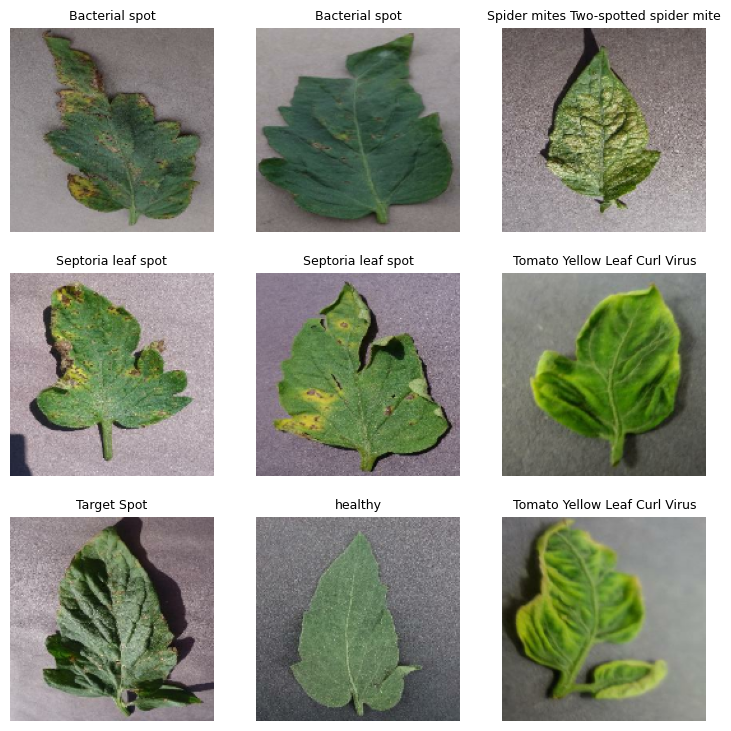

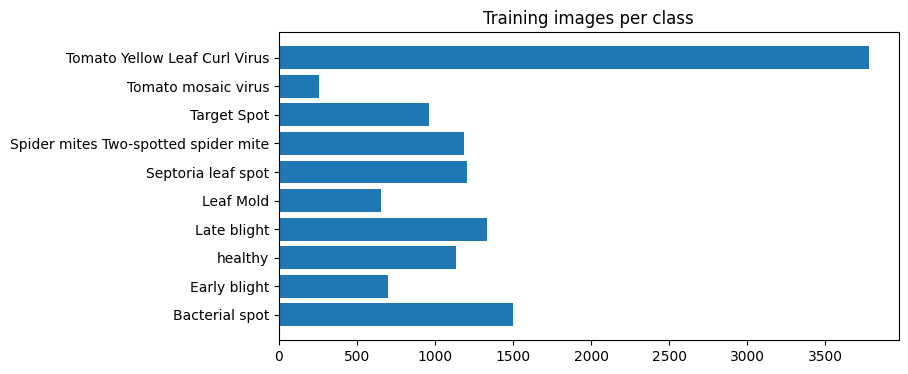

Total training images: 12712


In [ ]:
plt.figure(figsize=(9, 9))
for imgs, lbls in train_ds.take(1):
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(imgs[i].numpy())
        plt.title(short_names[int(lbls[i])], fontsize=9)
        plt.axis('off')
plt.show()

labels = np.concatenate([y.numpy() for _, y in train_ds])
counts = np.bincount(labels, minlength=num_classes)
plt.figure(figsize=(8, 4))
plt.barh(short_names, counts)
plt.title('Training images per class')
plt.show()
print('Total training images:', counts.sum())

## 3. Baseline CNN

In [ ]:
# Augmentation is active during training only
augment = keras.Sequential([
    layers.RandomFlip('horizontal_and_vertical'),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

cnn = keras.Sequential([
    keras.Input(shape=(IMG, IMG, 3)),
    augment,
    layers.Rescaling(1. / 255),
    layers.Conv2D(32, 3, activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation='relu'),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dropout(0.3),
    layers.Dense(128, activation='relu'),
    layers.Dense(num_classes, activation='softmax'),
])
cnn.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
cnn.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 158, 158, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 79, 79, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 77, 77, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 38, 38, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 36, 36, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 41472)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 41472)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     5,308,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,403,082 (20.61 MB)

 Trainable params: 5,403,082 (20.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history_cnn = cnn.fit(train_ds, validation_data=val_ds, epochs=10)

Epoch 1/10
    398/Unknown 26s 30ms/step - accuracy: 0.5215 - loss: 1.4039

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


398/398 ━━━━━━━━━━━━━━━━━━━━ 51s 94ms/step - accuracy: 0.6359 - loss: 1.0602 - val_accuracy: 0.7331 - val_loss: 0.7842
Epoch 2/10
398/398 ━━━━━━━━━━━━━━━━━━━━ 46s 30ms/step - accuracy: 0.8047 - loss: 0.5621 - val_accuracy: 0.6322 - val_loss: 1.2402
Epoch 3/10
398/398 ━━━━━━━━━━━━━━━━━━━━ 12s 30ms/step - accuracy: 0.8554 - loss: 0.4177 - val_accuracy: 0.7353 - val_loss: 0.9894
Epoch 4/10
398/398 ━━━━━━━━━━━━━━━━━━━━ 12s 30ms/step - accuracy: 0.8810 - loss: 0.3452 - val_accuracy: 0.8164 - val_loss: 0.5393
Epoch 5/10
398/398 ━━━━━━━━━━━━━━━━━━━━ 12s 31ms/step - accuracy: 0.8967 - loss: 0.2973 - val_accuracy: 0.7617 - val_loss: 0.7893
Epoch 6/10
398/398 ━━━━━━━━━━━━━━━━━━━━ 12s 31ms/step - accuracy: 0.9102 - loss: 0.2608 - val_accuracy: 0.8866 - val_loss: 0.3503
Epoch 7/10
398/398 ━━━━━━━━━━━━━━━━━━━━ 12s 31ms/step - accuracy: 0.9156 - loss: 0.2347 - val_accuracy: 0.8741 - val_loss: 0.3801
Epoch 8/10
398/398 ━━━━━━━━━━━━━━━━━━━━ 12s 31ms/step - accuracy: 0.9260 - loss: 0.2109 - val_accurac

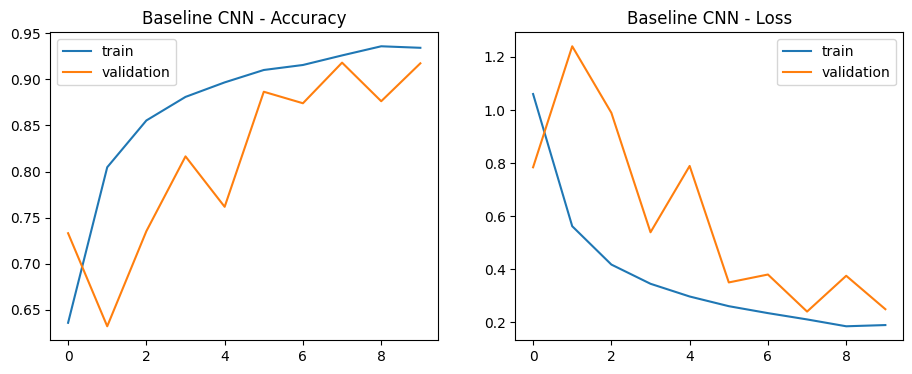

86/86 ━━━━━━━━━━━━━━━━━━━━ 24s 278ms/step - accuracy: 0.9166 - loss: 0.2423
Baseline CNN test accuracy: 91.66%


In [ ]:
def plot_history(h, title):
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(h.history['accuracy'], label='train')
    ax[0].plot(h.history['val_accuracy'], label='validation')
    ax[0].set_title(title + ' - Accuracy'); ax[0].legend()
    ax[1].plot(h.history['loss'], label='train')
    ax[1].plot(h.history['val_loss'], label='validation')
    ax[1].set_title(title + ' - Loss'); ax[1].legend()
    plt.show()

plot_history(history_cnn, 'Baseline CNN')
_, cnn_acc = cnn.evaluate(test_ds)
print(f'Baseline CNN test accuracy: {cnn_acc:.2%}')

## 4. Transfer learning: MobileNetV2

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/8
398/398 ━━━━━━━━━━━━━━━━━━━━ 24s 44ms/step - accuracy: 0.7242 - loss: 0.8384 - val_accuracy: 0.7863 - val_loss: 0.6305
Epoch 2/8
398/398 ━━━━━━━━━━━━━━━━━━━━ 15s 39ms/step - accuracy: 0.8368 - loss: 0.4832 - val_accuracy: 0.8253 - val_loss: 0.4995
Epoch 3/8
398/398 ━━━━━━━━━━━━━━━━━━━━ 15s 38ms/step - accuracy: 0.8601 - loss: 0.4093 - val_accuracy: 0.8399 - val_loss: 0.4560
Epoch 4/8
398/398 ━━━━━━━━━━━━━━━━━━━━ 20s 38ms/step - accuracy: 0.8719 - loss: 0.3778 - val_accuracy: 0.8473 - val_loss: 0.4373
Epoch 5/8
398/398 ━━━━━━━━━━━━━━━━━━━━ 15s 37ms/step - accuracy: 0.8743 - loss: 0.3646 - val_accuracy: 0.8359 - val_loss: 0.4683
Epoch 6/8
398/398 ━━━━━━━━━━━━━━━━━━━━ 15s 38ms/step - accuracy: 0.8783 - loss: 0.3571 - val_accuracy: 0.8499 - val_loss: 0.4316
Epoch 7/8
398/398 ━━━━━━━━━━━━━━━━━━━━ 15s 38ms/step - accuracy: 0.8780 - loss: 0.3486 - val_accuracy: 0.8557 - val_loss: 0.4333
Epoch 8/8
398/398 ━━━━━━━━━━━━━━━━━━━━ 15s 38ms/

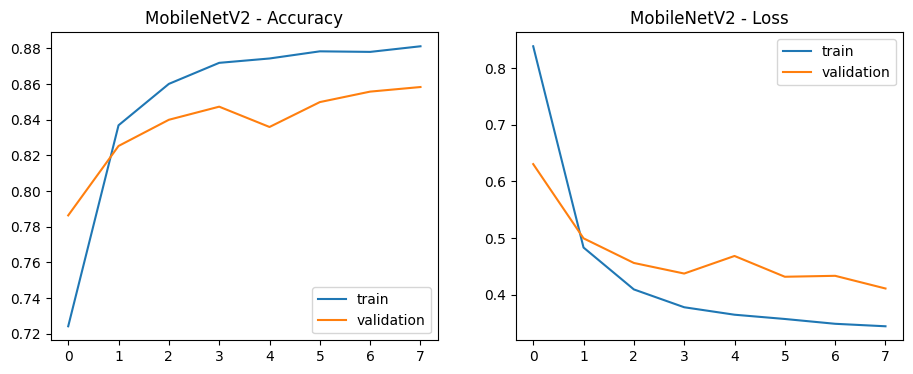

In [ ]:
# Pre-trained base is frozen; only the new classification head is trained
base = keras.applications.MobileNetV2(input_shape=(IMG, IMG, 3), include_top=False, weights='imagenet')
base.trainable = False

inputs = keras.Input(shape=(IMG, IMG, 3))
x = augment(inputs)
x = layers.Rescaling(1. / 127.5, offset=-1)(x)   # MobileNetV2 expects inputs in [-1, 1]
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(num_classes, activation='softmax')(x)
model = keras.Model(inputs, outputs)

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history_mn = model.fit(train_ds, validation_data=val_ds, epochs=8)
plot_history(history_mn, 'MobileNetV2')

## 5. Evaluation

86/86 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - accuracy: 0.8582 - loss: 0.4268
MobileNetV2 test accuracy: 85.82%
86/86 ━━━━━━━━━━━━━━━━━━━━ 5s 45ms/step
                                      precision    recall  f1-score   support

                      Bacterial spot       0.82      0.91      0.86       290
                        Early blight       0.94      0.46      0.61       158
                             healthy       0.75      0.98      0.85       219
                         Late blight       0.90      0.86      0.88       297
                           Leaf Mold       0.92      0.79      0.85       145
                  Septoria leaf spot       0.86      0.85      0.86       296
Spider mites Two-spotted spider mite       0.76      0.82      0.79       247
                         Target Spot       0.63      0.79      0.70       227
                 Tomato mosaic virus       0.95      0.76      0.85        54
       Tomato Yellow Leaf Curl Virus       1.00      0.94      0.97    

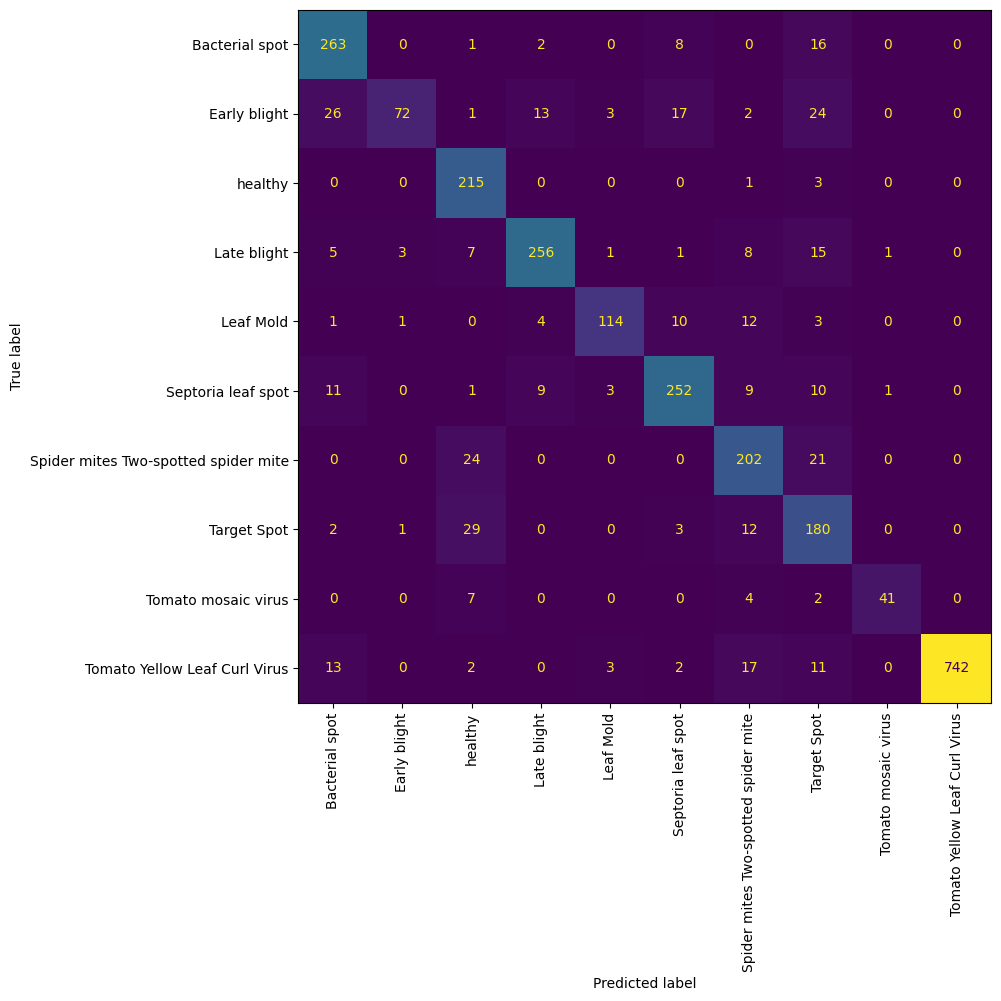

In [ ]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

_, mn_acc = model.evaluate(test_ds)
print(f'MobileNetV2 test accuracy: {mn_acc:.2%}')

y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_pred = np.argmax(model.predict(test_ds), axis=1)
print(classification_report(y_true, y_pred, target_names=short_names))

fig, ax = plt.subplots(figsize=(9, 9))
ConfusionMatrixDisplay.from_predictions(y_true, y_pred, display_labels=short_names,
                                        xticks_rotation=90, ax=ax, colorbar=False)
plt.show()

In [ ]:
display(pd.DataFrame({
    'Model': ['Baseline CNN', 'MobileNetV2'],
    'Test accuracy': [f'{cnn_acc:.2%}', f'{mn_acc:.2%}'],
}))

,Model,Test accuracy
0,Baseline CNN,91.66%
1,MobileNetV2,85.82%


## 6. Testing on unseen samples (green = correct, red = wrong)

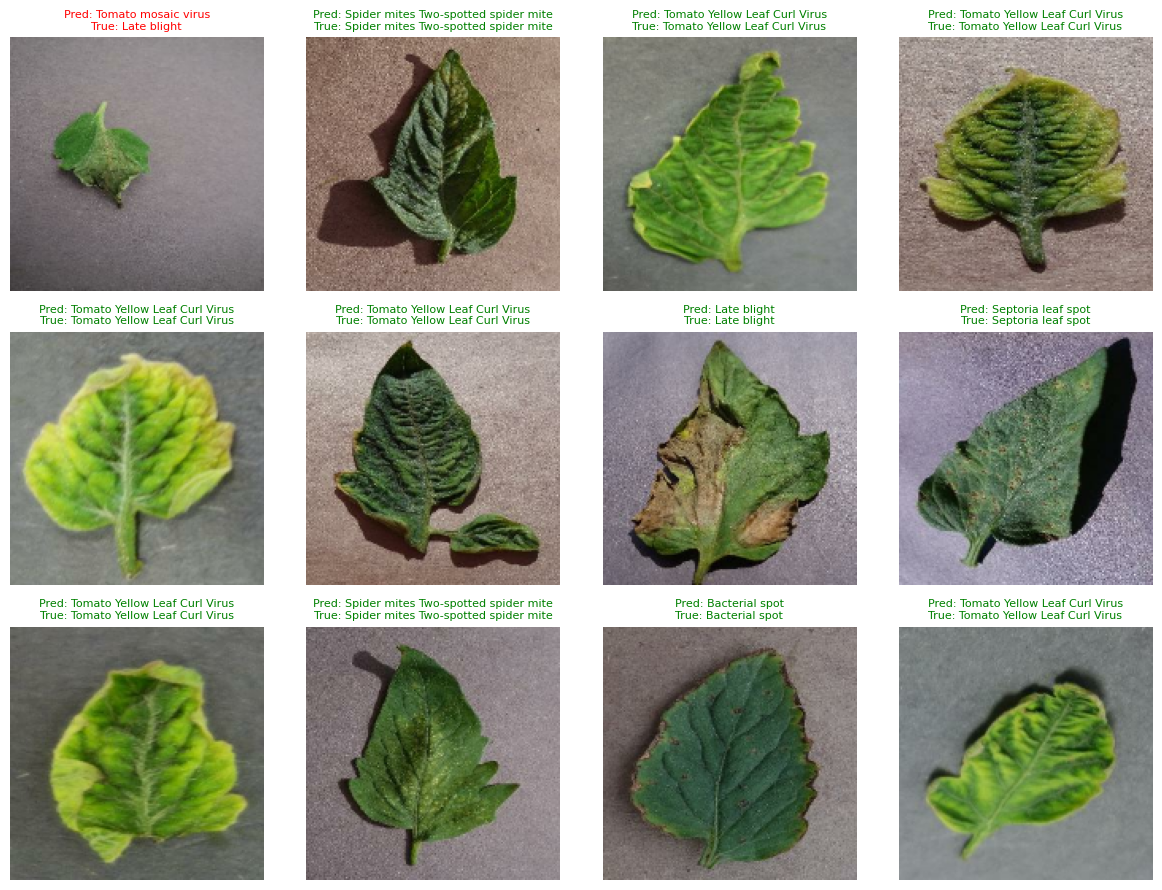

In [ ]:
plt.figure(figsize=(12, 9))
for imgs, lbls in test_ds.shuffle(50).take(1):
    probs = model.predict(imgs, verbose=0)
    for i in range(12):
        plt.subplot(3, 4, i + 1)
        plt.imshow(imgs[i].numpy()); plt.axis('off')
        pred, true = int(np.argmax(probs[i])), int(lbls[i])
        plt.title(f'Pred: {short_names[pred]}\nTrue: {short_names[true]}', fontsize=8,
                  color='green' if pred == true else 'red')
plt.tight_layout()
plt.show()

## 7. Interactive demo (upload your own leaf photo)

In [ ]:
!pip install -q gradio

In [ ]:
import gradio as gr

def predict_image(img):
    img = img.convert('RGB').resize((IMG, IMG))
    probs = model.predict(np.expand_dims(np.array(img), 0), verbose=0)[0]
    return {short_names[i]: float(probs[i]) for i in range(num_classes)}

demo = gr.Interface(
    fn=predict_image,
    inputs=gr.Image(type='pil', label='Upload a tomato leaf photo'),
    outputs=gr.Label(num_top_classes=3, label='Diagnosis'),
    title='Tomato Leaf Disease Detector',
)
demo.launch(share=True, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://f8fdc357df6177ca4c.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 8. Save the model

In [ ]:
model.save(SAVE_DIR + '/plant_model.keras')

from google.colab import files
files.download(SAVE_DIR + '/plant_model.keras')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>